# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

In [2]:
# Set up from midterm repo

# Setup: get the data and run the team's cleaning pipeline
import os
if not os.path.isdir('/content/ds2002-midterm'):
    !git clone -q https://github.com/ayanrasulova/ds2002-midterm.git

from pathlib import Path
import re

import pandas as pd

# find the project data folder, or in Colab
possible_data_dirs = [
    Path.cwd() / "data",
    Path.cwd().parent / "data",
    Path("/content/data"),
]
if Path("/content").is_dir():
    possible_data_dirs.extend(Path("/content").glob("**/data"))
DATA_DIR = next((path for path in possible_data_dirs if path.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError("could not find the data folder")
#read in data as plain text to avoid automatic conversion by Pandas
raw_transactions = pd.read_csv(
    DATA_DIR / "walmart_transactions.csv", dtype="string", keep_default_na=False
)
raw_stores = pd.read_csv(
    DATA_DIR / "store_locations.csv", dtype="string", keep_default_na=False
)
raw_products = pd.read_csv(
    DATA_DIR / "product_catalog.csv", dtype="string", keep_default_na=False
)

missing_tokens = {"", "NULL", "N/A", "NA", "NAN", "NONE"}
sku_groups = {
    "PT-12": ["PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"],
    "WTR-24": ["WTR-24", "WATER24PK", "WTR_24PK"],
    "BATT-100": ["BATT-100", "BAT-AA4", "BATT_AA_4PK"],
    "FLASH-01": ["FLASH-01", "LED-FLASH"],
    "BEER-24": ["BEER-24", "LTBEER24"],
    "BG-MONO": ["BG-MONO", "MONOPOLY-01", "GAME-MONO"],
    "CARDS-01": ["CARDS-01", "PLAYCARD-STD"],
    "STREAM-01": ["STREAM-01", "ROKU-STD"],
    "SOUP-CAN": ["SOUP-CAN", "CNSOUP-01"],
    "BREAD-WH": ["BREAD-WH", "WHITEBREAD"],
    "PB-16": ["PB-16", "PNUTBTR-16"],
    "CNDL-EM": ["CNDL-EM", "CANDLE-EMRG"],
    "FAID-01": ["FAID-01", "FIRSTAID-KIT"],
    "CHRG-PORT": ["CHRG-PORT", "PORTCHARGER"],
    "CHIPS-VP": ["CHIPS-VP", "CHIPVARIETY"],
    "PTOWEL-6": ["PTOWEL-6", "PAPERTOWEL6"],
    "TP-12": ["TP-12", "TOILETPAPER12"],
    "DIAP-S3": ["DIAP-S3", "DIAPERS-3"],
    "BFORM-01": ["BFORM-01", "BABYFORMULA"],
    "TARP-HD": ["TARP-HD", "HDTARP-01"],
}
# create a mapping of all known aliases to their canonical sku
sku_to_canonical = {
    alias.upper(): canonical
    for canonical, aliases in sku_groups.items()
    for alias in aliases
}
# standardize store ids and make empty strings and null-like values missing
def normalize_missing(frame):
    cleaned = frame.copy()
    for column in cleaned.select_dtypes(include=["object", "string"]).columns:
        values = cleaned[column].astype("string").str.strip()
        cleaned[column] = values.mask(values.str.upper().isin(missing_tokens), pd.NA)
    return cleaned

# standardize stores ids so they are all in 'FL' format to join
def normalize_store_id(values):
    text = values.astype("string").str.strip().str.upper()
    digits = text.str.extract(r"^FL[\s_-]?(\d{3})$", expand=False)
    return text.where(digits.isna(), "FL-" + digits)

# map spelling variations and capitalization to a canonical category name
def normalize_category(values):
    text = values.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    key = text.str.casefold().str.replace(r"[^a-z0-9]", "", regex=True)
    category_names = {
        "breakfastfoods": "Breakfast", "breakfast": "Breakfast",
        "emergencysupplies": "Emergency", "emergency": "Emergency",
        "alcoholicbeverages": "Alcohol", "alcohol": "Alcohol",
        "groceries": "Grocery", "grocery": "Grocery",
        "householdessentials": "Household", "household": "Household",
        "babyproducts": "Baby", "baby": "Baby",
        "entertainment": "Entertainment", "electronics": "Electronics",
        "health": "Health", "snacks": "Snacks",
    }
    return key.map(category_names).fillna(text.str.title()).astype("string")

#convert numeric fields to numbers, removing currency symbols and commas
def to_number(values):
    text = values.astype("string").str.strip().str.replace(r"[$,~]", "", regex=True)
    return pd.to_numeric(text, errors="coerce")

def clean_transactions(transaction_data, store_data):
    before_rows = len(transaction_data)
    transactions = normalize_missing(transaction_data)
    missing_rows = int(transactions.isna().any(axis=1).sum())

    # keep the first copy of each transaction id
    transactions["transaction_id"] = transactions["transaction_id"].str.strip().str.upper()
    before_dedup = len(transactions)
    transactions = transactions.drop_duplicates(subset=["transaction_id"], keep="first").copy()
    duplicate_rows = before_dedup - len(transactions)

    # clean store values, drop duplicates
    stores = normalize_missing(store_data)
    old_store_ids = stores["store_id"].copy()
    stores["store_id"] = normalize_store_id(stores["store_id"])
    store_ids_changed = int(old_store_ids.ne(stores["store_id"]).fillna(False).sum())
    before_store_dedup = len(stores)
    stores = stores.drop_duplicates(subset=["store_id"], keep="first").copy()
    duplicate_stores = before_store_dedup - len(stores)

    # clean store ids to match the cleaned store file
    old_transaction_store_ids = transactions["store_id"].copy()
    transactions["store_id"] = normalize_store_id(transactions["store_id"])
    transaction_store_ids_changed = int(
        old_transaction_store_ids.ne(transactions["store_id"]).fillna(False).sum()
    )

    transactions["source_sku"] = transactions["sku"].astype("string").str.strip().str.upper()
    transactions["canonical_sku"] = transactions["source_sku"].map(sku_to_canonical).fillna(
        transactions["source_sku"]
    )
    sku_rows_changed = int(
        transactions["source_sku"].ne(transactions["canonical_sku"]).fillna(False).sum()
    )
    old_categories = transactions["category"].copy()
    transactions["category"] = normalize_category(transactions["category"])
    category_rows_changed = int(
        old_categories.ne(transactions["category"]).fillna(False).sum()
    )
    transactions["quantity"] = to_number(transactions["quantity"])
    transactions["unit_price"] = to_number(transactions["unit_price"])
    numeric_rows_touched = int(
        (transactions["quantity"].notna() | transactions["unit_price"].notna()).sum()
    )

    # parse mixed dates and convert local times to utc
    parsed = pd.to_datetime(transactions["timestamp"], format="mixed", errors="coerce")
    if parsed.dt.tz is None:
        parsed = parsed.dt.tz_localize(
            "America/New_York", ambiguous="NaT", nonexistent="NaT"
        )
    transactions["timestamp_local"] = parsed
    transactions["timestamp_utc"] = parsed.dt.tz_convert("UTC")

    # keep negative quantities aside for review
    negative_mask = transactions["quantity"].lt(0).fillna(False)
    quarantined = transactions.loc[negative_mask].copy()
    cleaned = transactions.loc[~negative_mask].copy()
    cleaned = cleaned.merge(
        stores[["store_id", "store_name", "city", "state", "region"]],
        on="store_id", how="left", validate="many_to_one",
    )

    decisions = pd.DataFrame([
        {"decision": "missing values", "action": "kept null-like fields as missing", "rows_touched": missing_rows},
        {"decision": "duplicate transactions", "action": "kept first transaction id", "rows_touched": duplicate_rows},
        {"decision": "store ids", "action": "standardized transaction ids", "rows_touched": transaction_store_ids_changed},
        {"decision": "store file", "action": "standardized ids and removed duplicate stores", "rows_touched": store_ids_changed + duplicate_stores},
        {"decision": "sku aliases", "action": "mapped source skus to canonical skus", "rows_touched": sku_rows_changed},
        {"decision": "categories", "action": "standardized names and capitalization", "rows_touched": category_rows_changed},
        {"decision": "numeric fields", "action": "converted quantity and price to numbers", "rows_touched": numeric_rows_touched},
        {"decision": "timestamps", "action": "parsed and converted valid times to utc", "rows_touched": int(parsed.notna().sum())},
        {"decision": "missing timestamps", "action": "left unparsed times as missing", "rows_touched": int(parsed.isna().sum())},
        {"decision": "negative quantities", "action": "moved rows to transactions_quarantined", "rows_touched": len(quarantined)},
    ])
    return cleaned, quarantined, stores, decisions, before_rows

# run the cleaning pipeline
transactions_clean, transactions_quarantined, stores, decision_log, rows_before = clean_transactions(
    raw_transactions, raw_stores
)
print("rows before cleaning:", rows_before)
print("duplicate transaction rows removed:", int(decision_log.loc[decision_log["decision"] == "duplicate transactions", "rows_touched"].iloc[0]))
print("negative quantity rows quarantined:", len(transactions_quarantined))
print("rows after cleaning:", len(transactions_clean))

rows before cleaning: 25562
duplicate transaction rows removed: 30
negative quantity rows quarantined: 130
rows after cleaning: 25402


## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

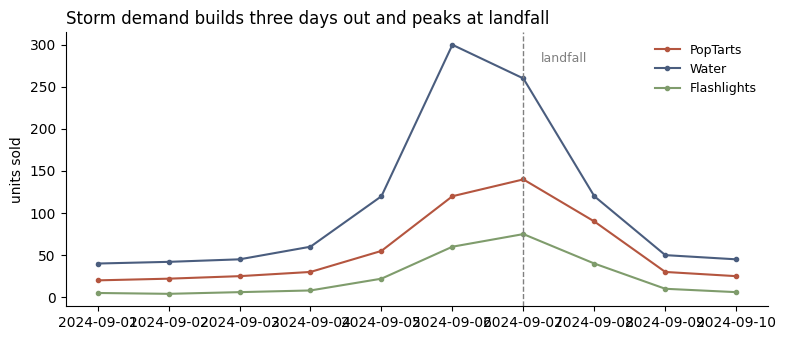

In [3]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

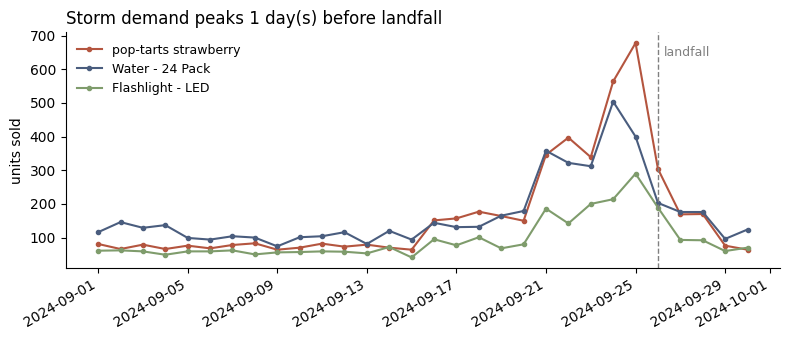

In [4]:
# TODO

import numpy as np, matplotlib.pyplot as plt

landfall_real = pd.Timestamp('2024-09-26')

sales = transactions_clean.dropna(subset=['timestamp_local']).copy()
sales['date'] = sales['timestamp_local'].dt.tz_localize(None).dt.normalize()
names = sales.dropna(subset=['product_name']).groupby('canonical_sku')['product_name'].first()

sales_daily = sales.pivot_table(index='date', columns='canonical_sku', values='quantity',
                                aggfunc='sum', fill_value=0)
sales_daily = sales_daily.reindex(pd.date_range(sales_daily.index.min(), sales_daily.index.max(), freq='D'),
                                  fill_value=0)

picks = ['PT-12', 'WTR-24', 'FLASH-01']
peak_day = sales_daily[picks].sum(axis=1).idxmax()
days_out = (landfall_real - peak_day).days
if days_out > 0:
    when = f'{days_out} day(s) before landfall'
elif days_out == 0:
    when = 'on landfall day'
else:
    when = f'{-days_out} day(s) after landfall'

fig, ax = plt.subplots(figsize=(8, 3.5))
for sku, color in zip(picks, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(sales_daily.index, sales_daily[sku], marker='o', ms=3, color=color, label=names.get(sku, sku))
ax.axvline(landfall_real, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall_real + pd.Timedelta(hours=6), ax.get_ylim()[1] * 0.9),
            fontsize=9, color='gray')
ax.set_title(f'Storm demand peaks {when}', loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

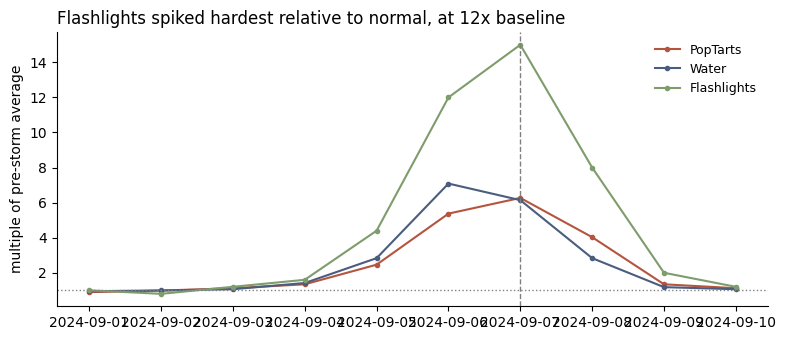

Flashlights    15.0
Water           7.1
PopTarts        6.3
dtype: float64


In [5]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

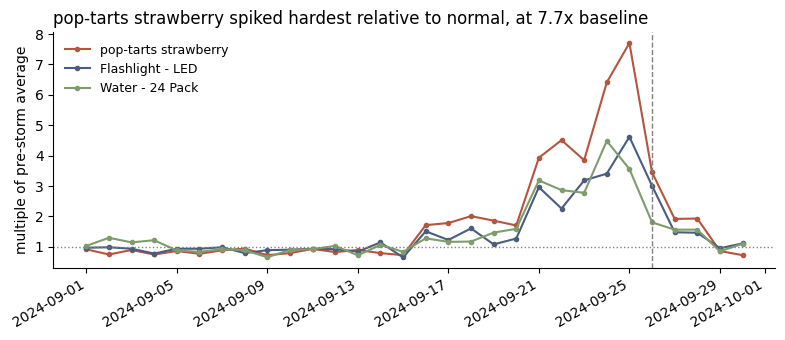

ranked by surge multiple:
canonical_sku
pop-tarts strawberry    7.7
Flashlight - LED        4.6
Water - 24 Pack         4.5
TARP - HEAVY DUTY       4.2
Emergency Candles       4.0
dtype: Float64

ranked by raw units:
canonical_sku
Water - 24 Pack          5037
pop-tarts strawberry     5005
AA Batteries (4-pack)    4154
Flashlight - LED         2814
Emergency Candles        2546
dtype: Int64

--- values for the Checkpoint cell ---
top product: pop-tarts strawberry
surge multiple: 7.7
baseline window: Sep 1 to Sep 18


In [6]:
# TODO

baseline_end = landfall_real - pd.Timedelta(days=7)
baseline_real = sales_daily[sales_daily.index < baseline_end].mean()
keep = baseline_real[baseline_real >= 1].index
indexed_real = sales_daily[keep] / baseline_real[keep]

surge = indexed_real.max().sort_values(ascending=False)
top3 = surge.index[:3]

fig, ax = plt.subplots(figsize=(8, 3.5))
for sku, color in zip(top3, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed_real.index, indexed_real[sku], marker='o', ms=3, color=color, label=names.get(sku, sku))
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall_real, ls='--', color='gray', lw=1)
ax.set_title(f'{names.get(top3[0], top3[0])} spiked hardest relative to normal, at {surge.iloc[0]:.1f}x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print('ranked by surge multiple:')
print(surge.rename(index=names).round(1).head(5))
print('\nranked by raw units:')
print(sales_daily[keep].sum().rename(index=names).sort_values(ascending=False).head(5))

print('\n--- values for the Checkpoint cell ---')
print('top product:', names.get(top3[0], top3[0]))
print('surge multiple:', round(float(surge.iloc[0]), 1))
print('baseline window:', f'{sales_daily.index.min():%b %-d} to {baseline_end - pd.Timedelta(days=1):%b %-d}')

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

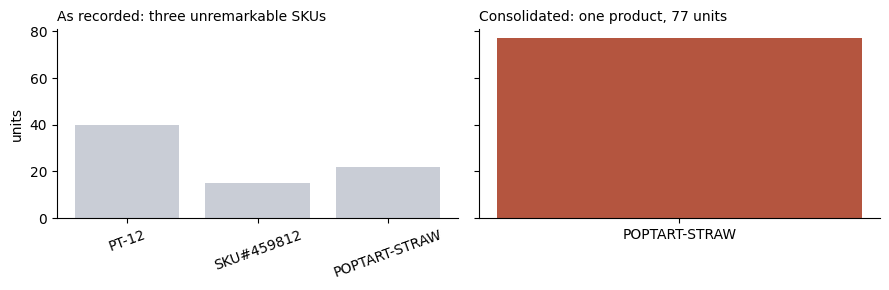

In [9]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

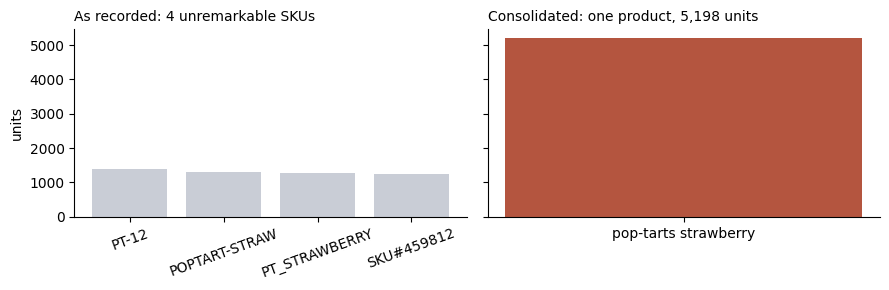

the consolidated total is 3.8x the largest single SKU


In [10]:
# TODO

family = 'PT-12'
pt = transactions_clean[transactions_clean['canonical_sku'] == family]
fragmented = pt.groupby('source_sku')['quantity'].sum().sort_values(ascending=False)
consolidated = pd.Series({names.get(family, family): fragmented.sum()})
multiple = fragmented.sum() / fragmented.max()

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(fragmented)} unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title(f'Consolidated: one product, {int(fragmented.sum()):,} units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(f'the consolidated total is {multiple:.1f}x the largest single SKU')

### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

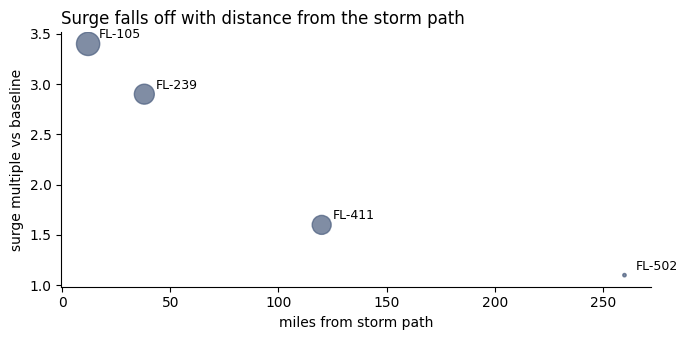

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [11]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

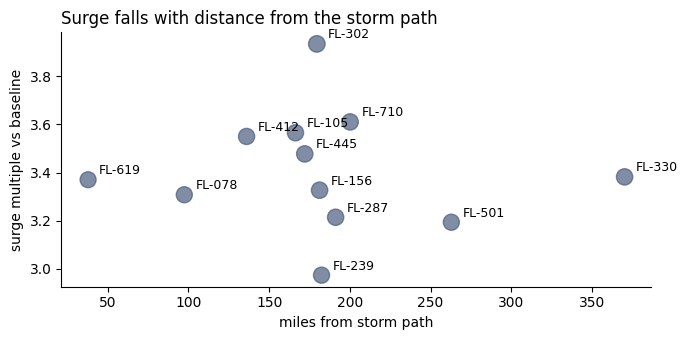

note the smallest bubble: FL-619 has only 1981 transactions,
so treat its multiple with caution.


,store_id,surge_multiple,transactions,latitude,longitude,miles_from_path
10,FL-619,3.37,1981,30.44,-84.28,37.86
0,FL-078,3.31,2001,29.65,-82.32,97.44
7,FL-412,3.55,2028,30.33,-81.66,136.02
1,FL-105,3.57,2043,27.95,-82.46,166.3
8,FL-445,3.48,2074,27.77,-82.64,172.04
5,FL-302,3.93,2123,28.04,-81.95,179.53
2,FL-156,3.33,2074,29.21,-81.02,181.23
3,FL-239,2.97,2010,28.54,-81.38,182.43
4,FL-287,3.21,2053,28.29,-81.41,191.17
11,FL-710,3.61,2066,30.42,-87.22,200.17


In [12]:
# TODO

storm_lat, storm_lon = 30.0, -83.9   # approximate landfall point (FL Big Bend); use your brief's if given

store_daily = sales.pivot_table(index='date', columns='store_id', values='quantity',
                                aggfunc='sum', fill_value=0)
store_base = store_daily[store_daily.index < baseline_end].mean()
store_base = store_base[store_base > 0]

by_store_real = pd.DataFrame({
    'surge_multiple': store_daily[store_base.index].max() / store_base,
    'transactions': sales.groupby('store_id').size(),
})
coords = stores.set_index('store_id')[['latitude', 'longitude']].apply(to_number)
if 'FL-619' in coords.index and coords.loc['FL-619'].isna().any():
    coords.loc['FL-619'] = [30.4383, -84.2807]   # same Tallahassee fill as the weather cell
by_store_real = by_store_real.join(coords).dropna()

lat1, lon1 = np.radians(by_store_real['latitude']), np.radians(by_store_real['longitude'])
lat2, lon2 = np.radians(storm_lat), np.radians(storm_lon)
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
by_store_real['miles_from_path'] = 3958.8 * 2 * np.arcsin(np.sqrt(a))
by_store_real = by_store_real.rename_axis('store_id').reset_index()

trend = by_store_real['miles_from_path'].corr(by_store_real['surge_multiple'])
fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store_real['transactions'] / 15
ax.scatter(by_store_real['miles_from_path'], by_store_real['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store_real.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title(f'Surge {"falls" if trend < 0 else "does not fall"} with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

smallest = by_store_real.nsmallest(1, 'transactions').iloc[0]
print(f'note the smallest bubble: {smallest.store_id} has only {int(smallest.transactions)} transactions,')
print('so treat its multiple with caution.')
display(by_store_real.sort_values('miles_from_path').round(2))

### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [13]:
# Checkpoint
top_product = 'Strawberry Pop-Tarts'         # TODO: your biggest mover
surge_multiple = 7.7        # TODO: how many times baseline
baseline_window = '09/01 - 09/18'     # TODO: e.g. '14 days before Sept 4'
charts_ready = 4          # TODO: how many presentation-ready charts you have

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)

top product: Strawberry Pop-Tarts
surge multiple: 7.7
baseline window: 09/01 - 09/18
charts ready: 4


The strawberry poptarts were found to have increases 7.7x in sales from there baseline whcih was recorded from 09.01 to 09/18. There are four charts ready to display this data.